# Step 5.5: Dust Reddening

Inference only. The Step 4 checkpoints are reloaded and never modified, and Step 5.0 has confirmed that the reload reproduces the clean baseline.

**The perturbation.** Each spectrum is multiplied by an interstellar extinction curve and then renormalised by the median of its positive pixels, exactly as the Step 2 pipeline would treat a genuinely reddened observation:

$$
f_{\text{reddened}}(\lambda) = f(\lambda) \cdot 10^{-0.4\,E(B-V)\,k(\lambda)}
$$

with $k(\lambda) = R_V\,a(x) + b(x)$ from the Cardelli, Clayton and Mathis parameterisation, $x = 1/\lambda\,[\mu\mathrm{m}^{-1}]$, and $R_V = 3.1$ for diffuse Galactic dust.

**Why this attack is different in kind from the four before it.** Steps 5.1 to 5.4 applied corruptions that destroy information: an outlier, an erased window, a displacement, a loss of resolution. Reddening destroys nothing. It applies a smooth, monotone, invertible multiplicative distortion that leaves every line intact and every pixel usable, and it is the one perturbation in the study that a real survey applies to real data as a matter of course. What makes it dangerous is not information loss but **degeneracy**: reddening makes a spectrum redder, and a cooler star is redder, so the perturbation moves the input along the direction the target itself varies in. This is the classic temperature–extinction degeneracy of stellar spectroscopy, and it is the reason a signed bias rather than an RMSE is the quantity of interest here.

**Why a signed bias is the primary metric.** Step 5.0 added signed bias to the reported quantities with this artefact chiefly in mind. A symmetric error measure records that predictions have become noisier; only a signed measure records that an entire catalogue has been pushed cool. The latter is what corrupts a downstream astronomical result, and it accumulates over all 18,898 spectra rather than averaging out.

**The first-order control.** A continuum tilt, a multiplication by a straight line in $\lambda$, distorts the continuum as smoothly as reddening does, so it is run here as a control rather than as a separate artefact: Sweep B applies the extinction law **linearised in $\lambda$ and matched at the two ends of the band**, so the colour excess across the whole range is identical to Sweep A while the curvature of the real law is removed. The difference between the two sweeps is the part of the damage that requires the true shape of the extinction curve rather than merely its mean slope. On this band the distinction is not cosmetic. Measured on the law itself, the local slope $dk/d\lambda$ at 3600 Å is **3.75 times** that at 10300 Å, and the largest departure of the straight line from the true curve is **20% of the entire colour excess across the band**. A straight line is therefore a poor approximation of the law even though both are smooth and monotone, and the two sweeps are not near-duplicates of one another.

**In the paper.** Signed bias against colour excess for reddening and de-reddening (Sweeps A and C, Fig. 3c), the full law against its linearisation (Sweep B, Fig. 3d, `step55_first_order_control.csv`), the per-regime biases at $E(B-V) = 0.5$, the paired tests, and the change in blue-to-red flux ratio printed in Section 5.5.3. The renormalisation control (Sweep D) supports the statement that renormalisation is essential. Per-spectrum predictions are written to disk, so any configuration can be re-analysed without re-running the attack.

## 5.5.1 Configuration

Four sweeps.

**Sweep A** applies the full CCM law at nine values of $E(B-V)$, from 0.02 — below the extinction of a high-latitude field — to 1.2, which is heavier than most of the disk.

**Sweep B** applies the law linearised in $\lambda$ and matched at both ends of the band, at the same nine levels. It is the first-order control described above.

**Sweep C** applies negative $E(B-V)$, that is, de-reddening. It is not a physical operation — it is the directional control, and it plays the role that the blueshift sweep played in Step 5.3. If the bias is a genuine consequence of the colour change and not an artefact of the operation, it must reverse sign here.

**Sweep D** withholds the median renormalisation at three levels. Reddening changes the median of a spectrum substantially, far more than a blur does, so unlike Step 5.4 this control is not expected in advance to be negligible.

The perturbation is deterministic given $E(B-V)$, so there is no sampling variance of the kind checked in Step 5.1. As in every previous step, the perturbed tensor is built once at each level and pushed through all ten networks before the next one is generated.

In [1]:
import os
import json
import time
import math

import numpy as np
import pandas as pd
import h5py
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ==========================================
# CONFIGURATION
# ==========================================
DATA_DIR    = 'data'
RESULTS_DIR = 'results'
CKPT_DIR    = 'checkpoints'
STEP55_DIR  = os.path.join(RESULTS_DIR, 'step55')

MODELS = ['Conv-Pool', 'Conv-Attn']
SEEDS  = [0, 1, 2, 3, 4]

BATCH_SIZE = 256

# ---- attack ------------------------------------------------------------------
ATTACK      = 'dust_reddening'
ATTACK_SEED = 55          # the extinction curve is deterministic

R_V = 3.1                 # diffuse Galactic dust

EBV_LEVELS    = [0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 0.8, 1.2]   # sweep A and B
EBV_NEGATIVE  = [-0.05, -0.1, -0.2, -0.5]                          # sweep C
EBV_NO_RENORM = [0.1, 0.3, 0.8]                                    # sweep D

CATASTROPHIC_K = 300.0    # same convention as Step 5.0 onward

METRIC_COLS = ['rmse_K', 'mae_K', 'bias_K', 'p99_abs_K', 'gross_fail_frac']

COLORS = {'Conv-Pool': '#0173B2', 'Conv-Attn': '#DE8F05'}

# ==========================================
# PLOT STYLE
# ==========================================
sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.dpi': 130,
})

W_DOUBLE = 7.0

# ==========================================
# LOAD METADATA AND THE STEP 5.0 BASELINE
# ==========================================
import common
device = common.get_device()

os.makedirs(STEP55_DIR, exist_ok=True)

with open(os.path.join(DATA_DIR, 'preprocessing_meta.json')) as f:
    prep = json.load(f)
with open(os.path.join(RESULTS_DIR, 'step50_meta.json')) as f:
    meta50 = json.load(f)

TEFF_MIN    = prep['teff_min']
TEFF_RANGE  = prep['teff_range']
NOISE_FLOOR = meta50['label_noise_floor_K']
GRID        = prep['grid']
GRID_N      = GRID['seq_length']
REG_EDGES   = meta50['regime_edges_K']

assert meta50['gate_passed'], 'Step 5.0 integrity gate did not pass'
assert meta50['eval_batch_size'] == BATCH_SIZE, 'batch size differs from Step 5.0'
assert all(e in EBV_LEVELS for e in EBV_NO_RENORM), \
    'every renormalisation control must have a counterpart in sweep A'

clean_metrics = pd.read_csv(os.path.join(RESULTS_DIR, 'step50_baseline_metrics.csv'))

n_cfg = 2 * len(EBV_LEVELS) + len(EBV_NEGATIVE) + len(EBV_NO_RENORM)
print(f'Device  : {device}')
print(f'Sweep A : E(B-V) in {EBV_LEVELS}, full CCM law')
print(f'Sweep B : the same levels, law linearised in wavelength')
print(f'Sweep C : E(B-V) in {EBV_NEGATIVE}, de-reddening, directional control')
print(f'Sweep D : E(B-V) in {EBV_NO_RENORM}, renormalisation withheld')
print(f'{n_cfg} configurations, {n_cfg * len(SEEDS) * len(MODELS)} forward passes')

Device  : cpu
Sweep A : E(B-V) in [0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 0.8, 1.2], full CCM law
Sweep B : the same levels, law linearised in wavelength
Sweep C : E(B-V) in [-0.05, -0.1, -0.2, -0.5], de-reddening, directional control
Sweep D : E(B-V) in [0.1, 0.3, 0.8], renormalisation withheld
25 configurations, 250 forward passes


## 5.5.2 Architectures

The two models are defined once, in `models.py`, and loaded through `common.py` exactly as in Step 5.0. The parity check halts the notebook if a definition has drifted from the one the checkpoints were written against.

In [2]:
from models import SharedStem, check_parameter_parity
import common

check_parameter_parity()


def load_model(model_name, seed):
    return common.load_model(model_name, seed, device, CKPT_DIR)


def predict(model, x, batch_size=BATCH_SIZE):
    """Forward a device-resident tensor; returns absolute temperatures in Kelvin."""
    return common.predict(model, x, TEFF_MIN, TEFF_RANGE, batch_size)


def metrics(pred_k, true_k):
    return common.metrics(pred_k, true_k, CATASTROPHIC_K)


Conv-Pool : 537,857 parameters
Conv-Attn : 540,161 parameters
difference: 2,304 (0.43%)


## 5.5.3 Test partition and the extinction law

The CCM parameterisation is piecewise in $x = 1/\lambda$. The adopted band, 3600–10300 Å, spans $x = 0.971$ to $2.778\ \mu\mathrm{m}^{-1}$, so it crosses the boundary at $x = 1.1$ between the near-infrared and optical branches and both are required. The implementation below is checked against the two properties that define the normalisation: $k(V) = R_V$ at 5500 Å, and $k(B) - k(V) = 1$ by the definition of the colour excess.

In [3]:
test_idx, X_test, y_true_k = common.load_test_split(DATA_DIR, GRID_N)
N_TEST = len(test_idx)
X_clean = torch.from_numpy(X_test).to(device)

regime = pd.cut(y_true_k, bins=REG_EDGES)
REG_LABELS = [str(c) for c in regime.categories]
regime_mask = {str(c): np.asarray(regime == c) for c in regime.categories}
assert not np.isnan(X_test).any(), 'NaN in the test tensor'

COLLAPSE_RMSE = float(np.std(y_true_k))
CEILING = {m: COLLAPSE_RMSE - float(
    clean_metrics[(clean_metrics.model == m) &
                  (clean_metrics.regime == 'all')]['rmse_K'].mean())
    for m in MODELS}
CEILING_MEAN = float(np.mean(list(CEILING.values())))
CLEAN_RMSE = {m: float(clean_metrics[(clean_metrics.model == m) &
                                     (clean_metrics.regime == 'all')]['rmse_K'].mean())
              for m in MODELS}

GRID_LO, GRID_HI = GRID['wave_start'], GRID['wave_end']
wavegrid = GRID_LO * (GRID_HI / GRID_LO) ** (np.arange(GRID_N) / (GRID_N - 1))


def ccm_k(lam_angstrom, r_v=R_V):
    """A(lambda)/E(B-V) from Cardelli, Clayton and Mathis.

    Piecewise in x = 1/lambda[micron]: the near-infrared branch below
    x = 1.1 and the optical polynomial above it. The adopted band crosses
    that boundary at 9091 A, so both are needed."""
    lam = np.atleast_1d(np.asarray(lam_angstrom, dtype=np.float64))
    x = 1.0e4 / lam
    a = np.zeros_like(x)
    b = np.zeros_like(x)

    ir = x < 1.1
    a[ir] = 0.574 * x[ir] ** 1.61
    b[ir] = -0.527 * x[ir] ** 1.61

    op = ~ir
    y = x[op] - 1.82
    a[op] = (1 + 0.17699 * y - 0.50447 * y ** 2 - 0.02427 * y ** 3
             + 0.72085 * y ** 4 + 0.01979 * y ** 5 - 0.77530 * y ** 6
             + 0.32999 * y ** 7)
    b[op] = (1.41338 * y + 2.28305 * y ** 2 + 1.07233 * y ** 3
             - 5.38434 * y ** 4 - 0.62251 * y ** 5 + 5.30260 * y ** 6
             - 2.09002 * y ** 7)
    return r_v * a + b


K_CURVE = torch.from_numpy(ccm_k(wavegrid)).to(device).float()

# linearised law: matched at both ends of the band, so the colour excess across
# the full range is identical and only the curvature differs
_k0, _k1 = float(K_CURVE[0]), float(K_CURVE[-1])
_frac = (wavegrid - GRID_LO) / (GRID_HI - GRID_LO)
K_LINEAR = torch.from_numpy(_k0 + (_k1 - _k0) * _frac).to(device).float()

# --- verification of the law --------------------------------------------------
_kv = float(ccm_k(5500.0)[0])
_kb = float(ccm_k(4400.0)[0])
print(f'k(V) at 5500 A : {_kv:.4f}   (should equal R_V = {R_V})')
print(f'k(B) - k(V)    : {_kb - _kv:.4f}   (should equal 1 by definition of E(B-V))')
assert abs(_kv - R_V) < 0.05, 'CCM normalisation at V is wrong'
assert abs((_kb - _kv) - 1.0) < 0.05, 'CCM colour-excess normalisation is wrong'

print()
print(f'band            : {GRID_LO:.0f}-{GRID_HI:.0f} A, '
      f'x = {1e4 / GRID_HI:.3f} to {1e4 / GRID_LO:.3f} 1/micron')
print(f'k at the ends   : {_k0:.4f} (blue) to {_k1:.4f} (red)')
print(f'branch crossing : x = 1.1 at {1e4 / 1.1:.0f} A, inside the band')
print()
print('extinction in magnitudes across the band, A(blue) - A(red):')
for e in EBV_LEVELS:
    print(f'  E(B-V) = {e:4.2f}: {e * (_k0 - _k1):5.2f} mag, '
          f'flux ratio blue/red changes by {10 ** (-0.4 * e * (_k0 - _k1)):.3f}')
print()
print('The linearised law matches at both ends by construction; the largest')
print(f'departure in between is {float((K_CURVE - K_LINEAR).abs().max()):.4f} in k,')
print(f'which is {100 * float((K_CURVE - K_LINEAR).abs().max()) / (_k0 - _k1):.1f}% of the')
print('total colour excess across the band.')
del _kv, _kb, _frac

k(V) at 5500 A : 3.0964   (should equal R_V = 3.1)
k(B) - k(V)    : 1.0096   (should equal 1 by definition of E(B-V))

band            : 3600-10300 A, x = 0.971 to 2.778 1/micron
k at the ends   : 4.8613 (blue) to 1.1942 (red)
branch crossing : x = 1.1 at 9091 A, inside the band

extinction in magnitudes across the band, A(blue) - A(red):
  E(B-V) = 0.02:  0.07 mag, flux ratio blue/red changes by 0.935
  E(B-V) = 0.05:  0.18 mag, flux ratio blue/red changes by 0.845
  E(B-V) = 0.10:  0.37 mag, flux ratio blue/red changes by 0.713
  E(B-V) = 0.15:  0.55 mag, flux ratio blue/red changes by 0.603
  E(B-V) = 0.20:  0.73 mag, flux ratio blue/red changes by 0.509
  E(B-V) = 0.30:  1.10 mag, flux ratio blue/red changes by 0.363
  E(B-V) = 0.50:  1.83 mag, flux ratio blue/red changes by 0.185
  E(B-V) = 0.80:  2.93 mag, flux ratio blue/red changes by 0.067
  E(B-V) = 1.20:  4.40 mag, flux ratio blue/red changes by 0.017

The linearised law matches at both ends by construction; the largest
depa

## 5.5.4 The perturbation

Multiply by the transmission and renormalise by the median of the positive pixels, the same median normalisation Step 2 applies to every spectrum. The renormalisation is not cosmetic here: extinction changes the median of a spectrum substantially, and a model trained on median-normalised inputs would otherwise see a global scale change it never encountered. What survives the renormalisation is the **shape** change, which is the physical content of reddening.

Three properties are checked below. A zero colour excess must be an exact no-op. The operation must be exactly invertible before renormalisation, since reddening by $E$ and then by $-E$ is multiplication by unity — this is what makes the de-reddening sweep a genuine directional control rather than a different attack. And the linearised law must agree with the full law at both ends of the band while differing in between, which is the property that makes Sweep B a first-order control rather than a weaker version of Sweep A.

In [4]:
def redden(x, ebv, law=None, renorm=True):
    """Multiply by the extinction curve and renormalise by the median.

    ebv > 0 reddens, ebv < 0 de-reddens. law defaults to the full CCM curve;
    pass K_LINEAR for the first-order control. x is left untouched."""
    if ebv == 0.0 and renorm:
        return x.clone()
    k = K_CURVE if law is None else law
    trans = torch.pow(10.0, -0.4 * float(ebv) * k).view(1, 1, -1)
    out = x * trans
    if renorm:
        tmp = out.clone()
        tmp[tmp <= 0] = float('nan')
        med = tmp.nanmedian(dim=-1, keepdim=True).values
        med = torch.nan_to_num(med, nan=1.0)
        med = torch.where(med.abs() < 1e-8, torch.ones_like(med), med)
        out = out / med
    return out


def run_tensor(x_att):
    """Evaluate all ten networks on one perturbed tensor."""
    out = np.empty((len(SEEDS), len(MODELS), N_TEST), dtype=np.float32)
    for si, seed in enumerate(SEEDS):
        for mi, m in enumerate(MODELS):
            model = load_model(m, seed)
            out[si, mi] = predict(model, x_att).astype(np.float32)
            del model
            if device.type == 'cuda':
                torch.cuda.empty_cache()
    return out


def path_ebv(ebv, variant='ccm'):
    s = 'm' if ebv < 0 else 'p'
    a = abs(float(ebv))
    return os.path.join(
        STEP55_DIR,
        f'preds_ebv{s}{int(a):01d}p{int(round((a - int(a)) * 1000)):03d}_{variant}.npz')


PATH_CLEAN = os.path.join(STEP55_DIR, 'preds_clean.npz')

# --- verification -------------------------------------------------------------
_probe = X_clean[:64]

assert torch.equal(redden(_probe, 0.0), _probe), 'E(B-V) = 0 is not a no-op'

# exact invertibility before renormalisation
_there = redden(_probe, 0.3, renorm=False)
_back = redden(_there, -0.3, renorm=False)
_inv = float((_back - _probe).abs().max())
print(f'redden then de-redden without renormalisation: max |diff| = {_inv:.3e}')
assert _inv < 1e-4, 'the extinction operation is not invertible'

# the linearised law matches at the ends and differs in between
assert abs(float(K_LINEAR[0] - K_CURVE[0])) < 1e-4, 'linear law mismatched at the blue end'
assert abs(float(K_LINEAR[-1] - K_CURVE[-1])) < 1e-4, 'linear law mismatched at the red end'
assert float((K_CURVE - K_LINEAR).abs().max()) > 0.05, \
    'the linear law is indistinguishable from the full law'

# the renormalised output stays finite and positive-median
for _e in [-0.5, 0.05, 1.2]:
    _o = redden(_probe, _e)
    assert torch.isfinite(_o).all(), f'non-finite output at E(B-V) = {_e}'
    assert float(_o.median()) > 0, f'non-positive median at E(B-V) = {_e}'

print('verified: zero is a no-op, the operation inverts exactly before')
print('renormalisation, the linearised law is matched at both ends and')
print('departs in between, and every output is finite')

print()
print('Effect of the median renormalisation, mean over the probe spectra:')
for _e in [0.1, 0.5, 1.2]:
    _raw = redden(_probe, _e, renorm=False)
    _med = float(_raw.median(dim=-1).values.mean())
    print(f'  E(B-V) = {_e:4.2f}: median before renormalisation = {_med:.4f}, '
          f'so the renormalisation divides by about {_med:.3f}')
del _probe, _there, _back, _o, _raw, _e

redden then de-redden without renormalisation: max |diff| = 2.384e-07
verified: zero is a no-op, the operation inverts exactly before
renormalisation, the linearised law is matched at both ends and
departs in between, and every output is finite

Effect of the median renormalisation, mean over the probe spectra:
  E(B-V) = 0.10: median before renormalisation = 0.7764, so the renormalisation divides by about 0.776
  E(B-V) = 0.50: median before renormalisation = 0.3006, so the renormalisation divides by about 0.301
  E(B-V) = 1.20: median before renormalisation = 0.0525, so the renormalisation divides by about 0.053


## 5.5.5 Sweeps

All four run on the full test partition. Results are written per level, so an interrupted run resumes rather than restarting. The clean predictions are cached alongside them.

In [5]:
_m = load_model(MODELS[0], SEEDS[0])
_t0 = time.time(); predict(_m, X_clean); _t = time.time() - _t0
del _m
if device.type == 'cuda':
    torch.cuda.empty_cache()

todo = sum(1 for e in EBV_LEVELS if not os.path.exists(path_ebv(e, 'ccm')))
todo += sum(1 for e in EBV_LEVELS if not os.path.exists(path_ebv(e, 'lin')))
todo += sum(1 for e in EBV_NEGATIVE if not os.path.exists(path_ebv(e, 'ccm')))
todo += sum(1 for e in EBV_NO_RENORM if not os.path.exists(path_ebv(e, 'raw')))
todo += 0 if os.path.exists(PATH_CLEAN) else 1

print(f'one forward pass : {_t:.1f} s')
print(f'tensors to run   : {todo}  ({todo * len(SEEDS) * len(MODELS)} forward passes)')
print(f'projected total  : {_t * todo * len(SEEDS) * len(MODELS) * 1.4 / 60:.0f} min')
print('Configurations already on disk are skipped.')

one forward pass : 16.2 s
tensors to run   : 26  (260 forward passes)
projected total  : 98 min
Configurations already on disk are skipped.


In [6]:
if os.path.exists(PATH_CLEAN):
    print('[skip] clean predictions')
else:
    t0 = time.time()
    preds = run_tensor(X_clean)
    np.savez_compressed(PATH_CLEAN, preds=preds, seeds=np.array(SEEDS),
                        models=np.array(MODELS))
    rmse = np.sqrt(((preds - y_true_k[None, None, :]) ** 2).mean(axis=-1))
    print('clean                ' + '   '.join(
        f'{m} {rmse[:, mi].mean():7.2f} K' for mi, m in enumerate(MODELS))
        + f'   ({time.time() - t0:.0f}s)')


def run_levels(levels, variant, label, law=None, renorm=True):
    for e in levels:
        p = path_ebv(e, variant)
        if os.path.exists(p):
            print(f'[skip] {label} E(B-V) = {e:+5.2f}')
            continue
        t0 = time.time()
        X_att = redden(X_clean, e, law=law, renorm=renorm)
        preds = run_tensor(X_att)
        del X_att
        np.savez_compressed(p, preds=preds, ebv=float(e), sweep=label,
                            variant=variant, renormalised=bool(renorm), r_v=R_V,
                            seeds=np.array(SEEDS), models=np.array(MODELS),
                            attack_seed=ATTACK_SEED)
        rmse = np.sqrt(((preds - y_true_k[None, None, :]) ** 2).mean(axis=-1))
        bias = (preds - y_true_k[None, None, :]).mean(axis=-1)
        print(f'{label} E(B-V) = {e:+5.2f}   ' + '   '.join(
            f'{m} {rmse[:, mi].mean():7.2f} K (bias {bias[:, mi].mean():+8.2f})'
            for mi, m in enumerate(MODELS)) + f'   ({time.time() - t0:.0f}s)')


run_levels(EBV_LEVELS, 'ccm', 'A')

clean                Conv-Pool   81.07 K   Conv-Attn   81.72 K   (212s)
A E(B-V) = +0.02   Conv-Pool   81.25 K (bias    -5.51)   Conv-Attn   81.94 K (bias    -5.19)   (223s)
A E(B-V) = +0.05   Conv-Pool   81.69 K (bias    -7.00)   Conv-Attn   82.46 K (bias    -6.49)   (217s)
A E(B-V) = +0.10   Conv-Pool   82.82 K (bias    -8.84)   Conv-Attn   83.78 K (bias    -7.89)   (213s)
A E(B-V) = +0.15   Conv-Pool   84.42 K (bias    -9.91)   Conv-Attn   85.71 K (bias    -8.39)   (214s)
A E(B-V) = +0.20   Conv-Pool   86.49 K (bias   -10.33)   Conv-Attn   88.31 K (bias    -8.12)   (214s)
A E(B-V) = +0.30   Conv-Pool   92.20 K (bias    -9.62)   Conv-Attn   95.57 K (bias    -5.72)   (213s)
A E(B-V) = +0.50   Conv-Pool  110.18 K (bias    -5.69)   Conv-Attn  117.37 K (bias    +2.74)   (212s)
A E(B-V) = +0.80   Conv-Pool  152.40 K (bias    -0.45)   Conv-Attn  163.81 K (bias    +9.10)   (213s)
A E(B-V) = +1.20   Conv-Pool  215.68 K (bias   -14.64)   Conv-Attn  237.74 K (bias   -12.08)   (214s)


In [7]:
run_levels(EBV_LEVELS, 'lin', 'B', law=K_LINEAR)

B E(B-V) = +0.02   Conv-Pool   81.32 K (bias    -6.23)   Conv-Attn   82.00 K (bias    -5.97)   (212s)
B E(B-V) = +0.05   Conv-Pool   81.92 K (bias    -8.89)   Conv-Attn   82.71 K (bias    -8.53)   (214s)
B E(B-V) = +0.10   Conv-Pool   83.48 K (bias   -12.81)   Conv-Attn   84.58 K (bias   -12.31)   (213s)
B E(B-V) = +0.15   Conv-Pool   85.61 K (bias   -16.00)   Conv-Attn   87.21 K (bias   -15.40)   (214s)
B E(B-V) = +0.20   Conv-Pool   88.17 K (bias   -18.39)   Conv-Attn   90.55 K (bias   -17.78)   (212s)
B E(B-V) = +0.30   Conv-Pool   94.50 K (bias   -21.12)   Conv-Attn   99.10 K (bias   -20.63)   (213s)
B E(B-V) = +0.50   Conv-Pool  112.14 K (bias   -22.22)   Conv-Attn  121.95 K (bias   -22.67)   (212s)
B E(B-V) = +0.80   Conv-Pool  150.62 K (bias   -27.27)   Conv-Attn  165.08 K (bias   -38.56)   (211s)
B E(B-V) = +1.20   Conv-Pool  216.54 K (bias   -64.94)   Conv-Attn  252.79 K (bias   -80.49)   (212s)


In [8]:
run_levels(EBV_NEGATIVE, 'ccm', 'C')

C E(B-V) = -0.05   Conv-Pool   81.06 K (bias    -0.90)   Conv-Attn   81.72 K (bias    -0.92)   (211s)
C E(B-V) = -0.10   Conv-Pool   81.85 K (bias    +3.24)   Conv-Attn   82.67 K (bias    +3.01)   (213s)
C E(B-V) = -0.20   Conv-Pool   86.08 K (bias   +12.64)   Conv-Attn   87.90 K (bias   +11.84)   (221s)
C E(B-V) = -0.50   Conv-Pool  109.36 K (bias   +38.38)   Conv-Attn  111.12 K (bias   +30.00)   (207s)


In [9]:
run_levels(EBV_NO_RENORM, 'raw', 'D', renorm=False)

D E(B-V) = +0.10   Conv-Pool   90.09 K (bias   +10.76)   Conv-Attn   95.01 K (bias    +7.23)   (216s)
D E(B-V) = +0.30   Conv-Pool  214.75 K (bias  +115.88)   Conv-Attn  202.18 K (bias   +60.03)   (216s)
D E(B-V) = +0.80   Conv-Pool 1009.85 K (bias  +575.42)   Conv-Attn  928.09 K (bias  +517.15)   (222s)


## 5.5.6 How large the distortion is, in model-free terms

Before any degradation is read, it is worth fixing how violent this perturbation is on the input side, because the measured effect on the predictions turns out to be small and the comparison is what makes that meaningful.

A single number does the work: the **ratio of blue to red flux**, which is what reddening changes and what a photometric temperature estimate would be built from. Section 5.5.3 already reported it. Any statement that the predictions moved by a few Kelvin should be read against that factor.

A comparison against a photometric colour-only temperature estimator is not made here. The blue-to-red flux ratio is **not monotone in temperature across 3500–9000 K** on this band — it turns over at the hot end, where the two bands no longer straddle the peak of the energy distribution — so a colour–temperature relation cannot be inverted without first restricting it to a branch, and building and validating such a relation properly is a piece of work in its own right rather than a control for this experiment. What remains is the direct statement: the input colour is altered by factors of several, and Section 5.5.7 reports what that does to the predictions.

In [10]:
BLUE_BAND = (4000.0, 5000.0)
RED_BAND  = (8000.0, 9000.0)

_blue = np.where((wavegrid >= BLUE_BAND[0]) & (wavegrid <= BLUE_BAND[1]))[0]
_red  = np.where((wavegrid >= RED_BAND[0]) & (wavegrid <= RED_BAND[1]))[0]
bi = torch.from_numpy(_blue).to(device)
ri = torch.from_numpy(_red).to(device)


def colour_index(x):
    """log10 of the blue-to-red band flux ratio, per spectrum."""
    b = x[:, 0, :].index_select(1, bi).mean(dim=1)
    r = x[:, 0, :].index_select(1, ri).mean(dim=1)
    return torch.log10((b / r.clamp(min=1e-8)).clamp(min=1e-8))


col_clean = colour_index(X_clean).cpu().numpy().astype(np.float64)

rows = []
for e in EBV_LEVELS + EBV_NEGATIVE:
    xa = redden(X_clean, e)
    ca = colour_index(xa).cpu().numpy().astype(np.float64)
    del xa
    d = float(np.mean(ca - col_clean))
    rows.append({'ebv': e, 'd_colour_dex': d, 'flux_ratio_factor': 10.0 ** d})
colour_change = pd.DataFrame(rows).sort_values('ebv')
colour_change.to_csv(os.path.join(RESULTS_DIR, 'step55_colour_change.csv'), index=False)

print(f'colour index: log10 of mean flux in {BLUE_BAND[0]:.0f}-{BLUE_BAND[1]:.0f} A '
      f'over {RED_BAND[0]:.0f}-{RED_BAND[1]:.0f} A')
print()
print('How far the input colour is moved, measured on the perturbed spectra:')
print(colour_change.round(4).to_string(index=False))
print()
print('The factor column is the blue-to-red flux ratio after reddening divided by its')
print('value before. These are the numbers the measured biases of the next section')
print('should be read against: a factor of several in the input colour, against a shift')
print('of a few Kelvin in the output.')

# the induced colour shift must match the extinction law analytically
_lam_b = float(wavegrid[_blue].mean())
_lam_r = float(wavegrid[_red].mean())
_kb, _kr = float(ccm_k(_lam_b)[0]), float(ccm_k(_lam_r)[0])
print()
print('Cross-check against the law, before renormalisation:')
for _e in [0.1, 0.5]:
    _pred = -0.4 * _e * (_kb - _kr)
    _meas = float((colour_index(redden(X_clean, _e, renorm=False))
                   - colour_index(X_clean)).mean())
    print(f'  E(B-V) = {_e:4.2f}: predicted {_pred:+.4f} dex, measured {_meas:+.4f} dex')
    assert abs(_pred - _meas) < 0.02, 'induced colour shift disagrees with the law'
del _lam_b, _lam_r, _kb, _kr, _e, _pred, _meas

colour index: log10 of mean flux in 4000-5000 A over 8000-9000 A

How far the input colour is moved, measured on the perturbed spectra:
  ebv  d_colour_dex  flux_ratio_factor
-0.50        0.4671             2.9316
-0.20        0.1859             1.5343
-0.10        0.0928             1.2382
-0.05        0.0464             1.1127
 0.02       -0.0185             0.9582
 0.05       -0.0463             0.8989
 0.10       -0.0925             0.8082
 0.15       -0.1386             0.7267
 0.20       -0.1847             0.6536
 0.30       -0.2766             0.5289
 0.50       -0.4595             0.3471
 0.80       -0.7317             0.1855
 1.20       -1.0906             0.0812

The factor column is the blue-to-red flux ratio after reddening divided by its
value before. These are the numbers the measured biases of the next section
should be read against: a factor of several in the input colour, against a shift
of a few Kelvin in the output.

Cross-check against the law, before renormalisati

## 5.5.7 Degradation

Every quantity is a difference against the Step 5.0 clean value, taken **within the same model and seed**, exactly as in Steps 5.1 to 5.4.

In [11]:
def degradation_from(paths):
    """paths: list of (level_dict, filepath)."""
    rows = []
    for level, p in paths:
        preds = np.load(p)['preds']
        for si, seed in enumerate(SEEDS):
            for mi, m in enumerate(MODELS):
                pr = preds[si, mi].astype(np.float64)
                rows.append({**level, 'model': m, 'seed': seed, 'regime': 'all',
                             **metrics(pr, y_true_k)})
                for lab, sel in regime_mask.items():
                    rows.append({**level, 'model': m, 'seed': seed, 'regime': lab,
                                 **metrics(pr[sel], y_true_k[sel])})
    att = pd.DataFrame(rows)
    deg = att.merge(clean_metrics[['model', 'seed', 'regime'] + METRIC_COLS],
                    on=['model', 'seed', 'regime'], suffixes=('', '_clean'))
    for c in METRIC_COLS:
        deg['d_' + c] = deg[c] - deg[c + '_clean']
    return deg


paths = []
for e in EBV_LEVELS:
    paths.append(({'sweep': 'A', 'ebv': float(e), 'variant': 'ccm'},
                  path_ebv(e, 'ccm')))
for e in EBV_LEVELS:
    paths.append(({'sweep': 'B', 'ebv': float(e), 'variant': 'lin'},
                  path_ebv(e, 'lin')))
for e in EBV_NEGATIVE:
    paths.append(({'sweep': 'C', 'ebv': float(e), 'variant': 'ccm'},
                  path_ebv(e, 'ccm')))
paths_d = []
for e in EBV_NO_RENORM:
    paths_d.append(({'sweep': 'D', 'ebv': float(e), 'variant': 'raw'},
                    path_ebv(e, 'raw')))

deg = degradation_from(paths)
deg_d = degradation_from(paths_d)
deg.to_csv(os.path.join(RESULTS_DIR, 'step55_degradation.csv'), index=False)
deg_d.to_csv(os.path.join(RESULTS_DIR, 'step55_degradation_norenorm.csv'), index=False)

ov = deg[deg.regime == 'all']
ov_A = ov[ov.sweep == 'A']
ov_B = ov[ov.sweep == 'B']
ov_C = ov[ov.sweep == 'C']
ov_d = deg_d[deg_d.regime == 'all']
print(f'{len(deg):,} rows for sweeps A, B and C; {len(deg_d):,} for the '
      f'renormalisation control')

2,200 rows for sweeps A, B and C; 300 for the renormalisation control


In [12]:
print('Sweep A — signed bias, the primary metric (K), mean and SD over seeds:')
print(ov_A.pivot_table(index='ebv', columns='model', values='d_bias_K',
                       aggfunc=['mean', 'std']).round(2).to_string())
print()
print('Sweep A — RMSE degradation (K):')
piv = ov_A.pivot_table(index='ebv', columns='model', values='d_rmse_K',
                       aggfunc=['mean', 'std'])
print(piv.round(2).to_string())
print()
print(f'Collapse ceiling on the RMSE degradation: ' +
      ', '.join(f'{m} {CEILING[m]:.0f} K' for m in MODELS))

Sweep A — signed bias, the primary metric (K), mean and SD over seeds:
           mean                 std          
model Conv-Attn Conv-Pool Conv-Attn Conv-Pool
ebv                                          
0.02      -1.04     -1.16      0.15      0.20
0.05      -2.34     -2.66      0.33      0.51
0.10      -3.74     -4.50      0.57      1.02
0.15      -4.24     -5.57      0.70      1.55
0.20      -3.97     -5.98      0.75      2.09
0.30      -1.57     -5.28      0.75      3.03
0.50       6.89     -1.35      2.26      3.58
0.80      13.25      3.89      3.50      6.76
1.20      -7.93    -10.30     10.21     13.89

Sweep A — RMSE degradation (K):
           mean                 std          
model Conv-Attn Conv-Pool Conv-Attn Conv-Pool
ebv                                          
0.02       0.21      0.18      0.07      0.05
0.05       0.73      0.62      0.18      0.18
0.10       2.06      1.75      0.29      0.51
0.15       3.98      3.34      0.36      0.95
0.20       6.58      5

In [13]:
tests = []
for sweep_label, sub_all in (('A', ov_A), ('B', ov_B), ('C', ov_C)):
    for e in sorted(sub_all.ebv.unique()):
        sub = sub_all[sub_all.ebv == e]
        a = sub[sub.model == 'Conv-Pool'].sort_values('seed')['d_bias_K'].values
        c = sub[sub.model == 'Conv-Attn'].sort_values('seed')['d_bias_K'].values
        diff = c - a
        sd = float(diff.std(ddof=1))
        t, p = stats.ttest_rel(c, a)
        ar = sub[sub.model == 'Conv-Pool'].sort_values('seed')['d_rmse_K'].values
        cr = sub[sub.model == 'Conv-Attn'].sort_values('seed')['d_rmse_K'].values
        dr = cr - ar
        sdr = float(dr.std(ddof=1))
        tr, pr_ = stats.ttest_rel(cr, ar)
        tests.append({'sweep': sweep_label, 'ebv': e,
                      'bias_gap_K': float(diff.mean()),
                      'bias_gap_over_sd': float(diff.mean() / sd) if sd > 0 else np.nan,
                      'bias_p': float(p),
                      'rmse_gap_K': float(dr.mean()),
                      'rmse_gap_over_sd': float(dr.mean() / sdr) if sdr > 0 else np.nan,
                      'rmse_p': float(pr_)})
tests = pd.DataFrame(tests)
tests.to_csv(os.path.join(RESULTS_DIR, 'step55_paired_tests.csv'), index=False)
print(tests.round(4).to_string(index=False))
print()
print('Gaps are Conv-Attn minus Conv-Pool, the convention of Steps 5.2 to 5.4.')
print('Both channels are tested because bias is the primary metric here while RMSE')
print('is what the earlier steps compared, and they need not agree.')

sweep   ebv  bias_gap_K  bias_gap_over_sd  bias_p  rmse_gap_K  rmse_gap_over_sd  rmse_p
    A  0.02      0.1187            0.4660  0.3563      0.0325            0.3200  0.5139
    A  0.05      0.3165            0.5086  0.3190      0.1150            0.4109  0.4102
    A  0.10      0.7606            0.6237  0.2356      0.3113            0.5178  0.3114
    A  0.15      1.3294            0.7451  0.1710      0.6385            0.6740  0.2063
    A  0.20      2.0091            0.8678  0.1243      1.1623            0.9000  0.1145
    A  0.30      3.7036            1.1094  0.0682      2.7176            1.4222  0.0335
    A  0.50      8.2383            1.6630  0.0205      6.5322            1.9812  0.0114
    A  0.80      9.3553            0.9594  0.0985     10.7540            1.7868  0.0162
    A  1.20      2.3737            0.1232  0.7966     21.4090            1.8414  0.0146
    B  0.02      0.0670            0.2505  0.6052      0.0333            0.3175  0.5169
    B  0.05      0.1656         

### The first-order control

Sweep B removes the curvature of the extinction law while preserving the colour excess across the band exactly. The difference between the two sweeps at the same $E(B-V)$ is therefore the part of the effect that requires the true shape of the law, and the ratio is the part that a simple linear tilt already accounts for.

In [14]:
rows = []
for e in EBV_LEVELS:
    for m in MODELS:
        full = ov_A[(ov_A.ebv == float(e)) &
                    (ov_A.model == m)].sort_values('seed')['d_bias_K'].values
        lin = ov_B[(ov_B.ebv == float(e)) &
                   (ov_B.model == m)].sort_values('seed')['d_bias_K'].values
        d = full - lin
        sd = float(d.std(ddof=1))
        t, p = stats.ttest_rel(full, lin)
        # A ratio of the two biases is undefined near the zero crossing of the
        # full-law bias and was dropped for that reason: it is the same failure
        # the per-regime ratio columns of Step 5.4 showed. The curvature term is
        # reported in Kelvin instead, together with its share of the larger of
        # the two magnitudes, which is bounded by construction.
        denom = max(abs(float(full.mean())), abs(float(lin.mean())))
        rows.append({'ebv': e, 'model': m,
                     'full_law_bias_K': float(full.mean()),
                     'linear_law_bias_K': float(lin.mean()),
                     'curvature_term_K': float(d.mean()),
                     'curvature_share': (abs(float(d.mean())) / denom
                                         if denom > 1e-9 else np.nan),
                     'ratio_to_sd': float(d.mean() / sd) if sd > 0 else np.nan,
                     'p_paired_t': float(p)})
first_order = pd.DataFrame(rows)
first_order.to_csv(os.path.join(RESULTS_DIR, 'step55_first_order_control.csv'),
                   index=False)
print('Full extinction law against its linearisation, signed bias (K):')
print(first_order.round(3).to_string(index=False))
print()
print('The curvature term is the bias under the full law minus the bias under a')
print('straight-line tilt carrying the identical colour excess across the band. It is')
print('the part of the response that requires the true shape of the extinction curve.')
print('The share column expresses it against the larger of the two biases, so it stays')
print('bounded even where the full-law bias passes through zero; a ratio of the two')
print('biases would not, which is why it is not reported.')
print()
print('If the curvature term is large and significant, a straight-line continuum tilt')
print('is not a simplified version of reddening but a different perturbation.')

Full extinction law against its linearisation, signed bias (K):
 ebv     model  full_law_bias_K  linear_law_bias_K  curvature_term_K  curvature_share  ratio_to_sd  p_paired_t
0.02 Conv-Pool           -1.163             -1.891             0.728            0.385       14.745       0.000
0.02 Conv-Attn           -1.045             -1.824             0.780            0.427       12.012       0.000
0.05 Conv-Pool           -2.658             -4.551             1.893            0.416       17.770       0.000
0.05 Conv-Attn           -2.342             -4.386             2.044            0.466       12.191       0.000
0.10 Conv-Pool           -4.501             -8.470             3.969            0.469       20.130       0.000
0.10 Conv-Attn           -3.740             -8.165             4.425            0.542       12.242       0.000
0.15 Conv-Pool           -5.571            -11.655             6.084            0.522       18.562       0.000
0.15 Conv-Attn           -4.242            -11.2

### The directional control

De-reddening is not a physical operation, but it is the test that the bias follows the colour change rather than the act of multiplying by something. If reddening pushes predictions cool because the spectrum looks cooler, then de-reddening must push them warm by a comparable amount at the same $|E(B-V)|$.

In [15]:
rows = []
for e in EBV_NEGATIVE:
    pos = abs(e)
    if pos not in EBV_LEVELS:
        continue
    for m in MODELS:
        neg_b = float(ov_C[(ov_C.ebv == float(e)) &
                           (ov_C.model == m)]['d_bias_K'].mean())
        pos_b = float(ov_A[(ov_A.ebv == float(pos)) &
                           (ov_A.model == m)]['d_bias_K'].mean())
        # normalised against the larger magnitude, for the same reason the
        # first-order control avoids a ratio of the two biases
        denom = max(abs(pos_b), abs(neg_b))
        rows.append({'abs_ebv': pos, 'model': m,
                     'reddened_bias_K': pos_b, 'dereddened_bias_K': neg_b,
                     'sum_K': pos_b + neg_b,
                     'asymmetry_share': ((pos_b + neg_b) / denom
                                         if denom > 1e-9 else np.nan)})
direction = pd.DataFrame(rows)
direction.to_csv(os.path.join(RESULTS_DIR, 'step55_direction_control.csv'), index=False)
print('Reddening against de-reddening at matched |E(B-V)|, signed bias (K):')
print(direction.round(3).to_string(index=False))
print()
print('A perfectly antisymmetric response would sum to zero. A sum that grows with')
print('|E(B-V)| is a real asymmetry, and there is a specific reason to expect one here:')
print('the training spectra already carry an unknown amount of interstellar reddening,')
print('so adding more moves the input toward a region the models have seen, while')
print('removing it moves them bluer than any star they were trained on. De-reddening')
print('is therefore the out-of-distribution direction, and the residual sum measures')
print('that rather than a failure of the operation, which was verified to invert')
print('exactly in Section 5.5.4.')

Reddening against de-reddening at matched |E(B-V)|, signed bias (K):
 abs_ebv     model  reddened_bias_K  dereddened_bias_K  sum_K  asymmetry_share
    0.05 Conv-Pool           -2.658              3.448  0.789            0.229
    0.05 Conv-Attn           -2.342              3.223  0.881            0.273
    0.10 Conv-Pool           -4.501              7.579  3.079            0.406
    0.10 Conv-Attn           -3.740              7.158  3.418            0.477
    0.20 Conv-Pool           -5.983             16.986 11.003            0.648
    0.20 Conv-Attn           -3.974             15.990 12.016            0.751
    0.50 Conv-Pool           -1.349             42.719 41.370            0.968
    0.50 Conv-Attn            6.890             34.150 41.040            1.202

A perfectly antisymmetric response would sum to zero. A sum that grows with
|E(B-V)| is a real asymmetry, and there is a specific reason to expect one here:
the training spectra already carry an unknown amount of inters

### The renormalisation control

In [16]:
rows = []
for e in EBV_NO_RENORM:
    for m in MODELS:
        with_n = ov_A[(ov_A.ebv == float(e)) &
                      (ov_A.model == m)].sort_values('seed')['d_bias_K'].values
        without = ov_d[(ov_d.ebv == float(e)) &
                       (ov_d.model == m)].sort_values('seed')['d_bias_K'].values
        d = with_n - without
        sd = float(d.std(ddof=1))
        t, p = stats.ttest_rel(with_n, without)
        rows.append({'ebv': e, 'model': m,
                     'renormalised_bias_K': float(with_n.mean()),
                     'raw_bias_K': float(without.mean()),
                     'difference_K': float(d.mean()),
                     'ratio_to_sd': float(d.mean() / sd) if sd > 0 else np.nan,
                     'p_paired_t': float(p)})
renorm_tab = pd.DataFrame(rows)
renorm_tab.to_csv(os.path.join(RESULTS_DIR, 'step55_renorm_control.csv'), index=False)
print('Median renormalisation applied against withheld, signed bias (K):')
print(renorm_tab.round(3).to_string(index=False))
print()
print('Unlike the blur of Step 5.4, extinction changes the median substantially, so this')
print('control is not expected in advance to be negligible. Sweep A applies the')
print('renormalisation because that is what the Step 2 pipeline does to a real reddened')
print('spectrum; the size of the difference here is how much that choice matters.')

Median renormalisation applied against withheld, signed bias (K):
 ebv     model  renormalised_bias_K  raw_bias_K  difference_K  ratio_to_sd  p_paired_t
 0.1 Conv-Pool               -4.501      15.105       -19.606       -1.666       0.020
 0.1 Conv-Attn               -3.740      11.376       -15.116       -2.004       0.011
 0.3 Conv-Pool               -5.278     120.228      -125.506       -2.099       0.009
 0.3 Conv-Attn               -1.574      64.179       -65.753       -0.948       0.101
 0.8 Conv-Pool                3.891     579.767      -575.876       -3.611       0.001
 0.8 Conv-Attn               13.246     521.301      -508.055       -1.701       0.019

Unlike the blur of Step 5.4, extinction changes the median substantially, so this
control is not expected in advance to be negligible. Sweep A applies the
renormalisation because that is what the Step 2 pipeline does to a real reddened
spectrum; the size of the difference here is how much that choice matters.


### By temperature regime

Reddening mimics cooling, so the regimes are not expected to respond alike. A hot star has the most to lose: its temperature is encoded largely in a steep blue continuum, which is exactly what extinction flattens. A cool star is already red, and the same colour excess moves it a smaller distance in temperature because the colour–temperature relation is shallower there.

This section carries the sharpest caveat on the aggregate result. An overall bias averages over regimes whose biases can have opposite sign, and that is exactly what happens here: the aggregate figure is small in part because the regimes cancel against one another, not only because each regime is individually small. The per-regime table is the one to read, and any statement about how well the models resist the temperature–extinction degeneracy has to be made regime by regime.

In [17]:
REPORT_AT = [0.05, 0.1, 0.2, 0.5]

for e in REPORT_AT:
    sub = deg[(deg.sweep == 'A') & (deg.ebv == e) & (deg.regime != 'all')]
    if len(sub) == 0:
        continue
    print()
    print(f'Per-regime signed bias (K), E(B-V) = {e:g}:')
    print(sub.pivot_table(index='regime', columns='model', values='d_bias_K',
                          aggfunc='mean').reindex(REG_LABELS).round(1).to_string())


Per-regime signed bias (K), E(B-V) = 0.05:
model         Conv-Attn  Conv-Pool
regime                            
(3500, 4000]       -2.7       -2.2
(4000, 4500]       -4.5       -4.0
(4500, 5000]       -4.8       -4.2
(5000, 5500]       -4.7       -4.6
(5500, 6000]       -1.4       -2.1
(6000, 6500]        0.4       -0.4
(6500, 7000]        2.9        2.3
(7000, 8000]       -5.4       -6.9
(8000, 9000]      -10.5      -11.1

Per-regime signed bias (K), E(B-V) = 0.1:
model         Conv-Attn  Conv-Pool
regime                            
(3500, 4000]       -5.2       -4.1
(4000, 4500]       -8.9       -8.1
(4500, 5000]       -9.4       -8.1
(5000, 5500]       -9.1       -8.6
(5500, 6000]       -1.4       -3.1
(6000, 6500]        3.3        1.2
(6500, 7000]        6.8        5.4
(7000, 8000]      -11.1      -14.3
(8000, 9000]      -21.8      -23.3

Per-regime signed bias (K), E(B-V) = 0.2:
model         Conv-Attn  Conv-Pool
regime                            
(3500, 4000]       -9.0       

In [18]:
for e in REPORT_AT:
    sub = deg[(deg.sweep == 'A') & (deg.ebv == e) & (deg.regime != 'all')]
    if len(sub) == 0:
        continue
    print()
    print(f'Per-regime RMSE degradation (K), E(B-V) = {e:g}:')
    tab = sub.pivot_table(index='regime', columns='model', values='d_rmse_K',
                          aggfunc='mean').reindex(REG_LABELS)
    tab['ratio'] = tab['Conv-Attn'] / tab['Conv-Pool']
    print(tab.round(2).to_string())
print()
print('As in Step 5.4, a ratio between two values that are both below the detection')
print('threshold carries no information and should not be interpreted.')


Per-regime RMSE degradation (K), E(B-V) = 0.05:
model         Conv-Attn  Conv-Pool  ratio
regime                                   
(3500, 4000]       0.17      -0.22  -0.78
(4000, 4500]       0.20      -0.09  -2.31
(4500, 5000]       0.54      -0.17  -3.15
(5000, 5500]       0.65       0.39   1.67
(5500, 6000]       0.76       0.82   0.93
(6000, 6500]       1.30       0.98   1.33
(6500, 7000]       0.58       0.58   0.99
(7000, 8000]      -0.23       0.64  -0.35
(8000, 9000]       4.66       4.82   0.97

Per-regime RMSE degradation (K), E(B-V) = 0.1:
model         Conv-Attn  Conv-Pool  ratio
regime                                   
(3500, 4000]       0.52      -0.26  -2.03
(4000, 4500]       0.88       0.05  18.86
(4500, 5000]       1.54       0.09  17.63
(5000, 5500]       1.84       1.14   1.61
(5500, 6000]       2.12       1.99   1.07
(6000, 6500]       3.01       2.19   1.37
(6500, 7000]       2.07       2.22   0.93
(7000, 8000]       0.72       2.93   0.25
(8000, 9000]      10.

## 5.5.8 Figures

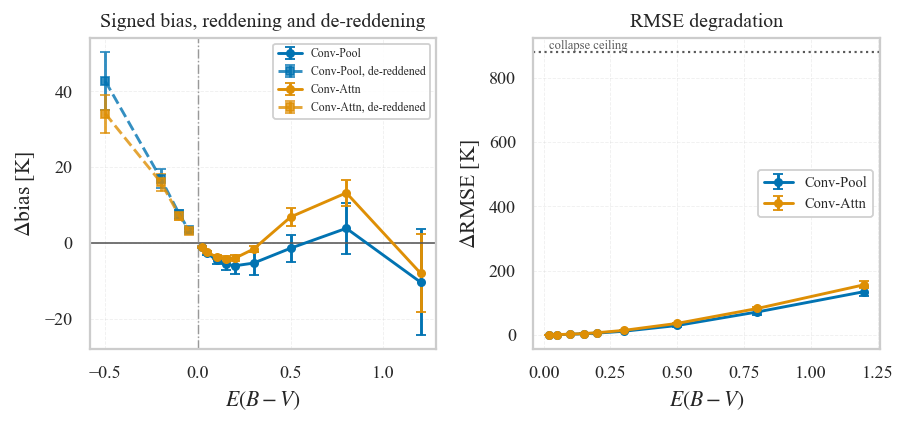

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(W_DOUBLE, 3.4))

for m in MODELS:
    g = ov_A[ov_A.model == m].groupby('ebv')['d_bias_K']
    axes[0].errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                     color=COLORS[m], marker='o', ms=4, lw=1.6, capsize=3, label=m)
    gc = ov_C[ov_C.model == m].groupby('ebv')['d_bias_K']
    axes[0].errorbar(gc.mean().index, gc.mean().values, yerr=gc.std().values,
                     color=COLORS[m], marker='s', ms=4, lw=1.6, ls='--', capsize=3,
                     alpha=0.8, label=f'{m}, de-reddened')
axes[0].axhline(0, color='0.35', lw=0.9)
axes[0].axvline(0, color='0.6', lw=0.8, ls='-.')
axes[0].set_xlabel(r'$E(B-V)$')
axes[0].set_ylabel(r'$\Delta$bias [K]')
axes[0].set_title('Signed bias, reddening and de-reddening', fontsize=11)
axes[0].legend(fontsize=6.5, framealpha=0.92)
axes[0].grid(True, ls='--', alpha=0.3, lw=0.5)

for m in MODELS:
    g = ov_A[ov_A.model == m].groupby('ebv')['d_rmse_K']
    axes[1].errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                     color=COLORS[m], marker='o', ms=4, lw=1.6, capsize=3, label=m)
axes[1].axhline(CEILING_MEAN, color='0.35', ls=':', lw=1.2)
axes[1].text(min(EBV_LEVELS), CEILING_MEAN, 'collapse ceiling', fontsize=7,
             va='bottom', color='0.35')
axes[1].set_xlabel(r'$E(B-V)$')
axes[1].set_ylabel(r'$\Delta$RMSE [K]')
axes[1].set_title('RMSE degradation', fontsize=11)
axes[1].legend(fontsize=8, framealpha=0.92)
axes[1].grid(True, ls='--', alpha=0.3, lw=0.5)

plt.tight_layout()
plt.show()

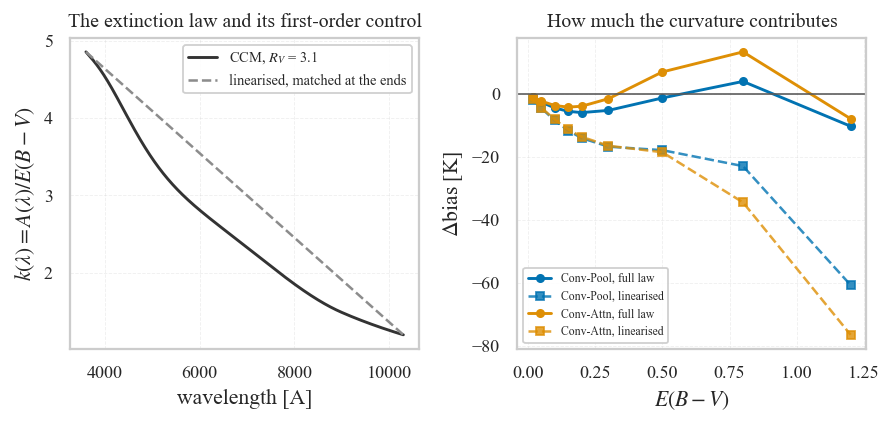

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(W_DOUBLE, 3.4))

axes[0].plot(wavegrid, K_CURVE.cpu().numpy(), color='0.2', lw=1.6,
             label='CCM, $R_V$ = 3.1')
axes[0].plot(wavegrid, K_LINEAR.cpu().numpy(), color='0.55', lw=1.4, ls='--',
             label='linearised, matched at the ends')
axes[0].set_xlabel('wavelength [A]')
axes[0].set_ylabel(r'$k(\lambda) = A(\lambda)/E(B-V)$')
axes[0].set_title('The extinction law and its first-order control', fontsize=11)
axes[0].legend(fontsize=8, framealpha=0.92)
axes[0].grid(True, ls='--', alpha=0.3, lw=0.5)

for m in MODELS:
    sub = first_order[first_order.model == m]
    axes[1].plot(sub['ebv'], sub['full_law_bias_K'], color=COLORS[m], marker='o',
                 ms=4, lw=1.6, label=f'{m}, full law')
    axes[1].plot(sub['ebv'], sub['linear_law_bias_K'], color=COLORS[m], marker='s',
                 ms=4, lw=1.4, ls='--', alpha=0.8, label=f'{m}, linearised')
axes[1].axhline(0, color='0.35', lw=0.9)
axes[1].set_xlabel(r'$E(B-V)$')
axes[1].set_ylabel(r'$\Delta$bias [K]')
axes[1].set_title('How much the curvature contributes', fontsize=11)
axes[1].legend(fontsize=6.5, framealpha=0.92)
axes[1].grid(True, ls='--', alpha=0.3, lw=0.5)

plt.tight_layout()
plt.show()

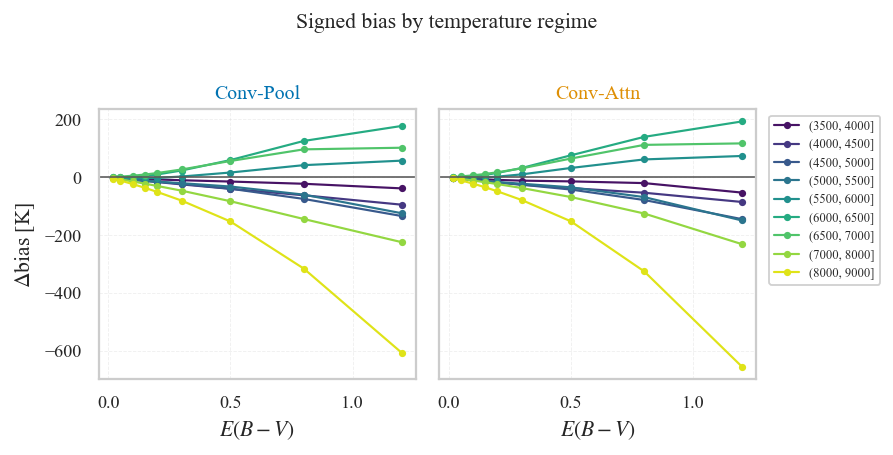

In [21]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(W_DOUBLE, 3.4), sharey=True)
cmap = plt.get_cmap('viridis')
colors_reg = cmap(np.linspace(0.05, 0.95, len(REG_LABELS)))

sub = deg[(deg.sweep == 'A') & (deg.regime != 'all')]
for ax, m in zip(axes, MODELS):
    for lab, cl in zip(REG_LABELS, colors_reg):
        g = sub[(sub.model == m) & (sub.regime == lab)].groupby('ebv')['d_bias_K'].mean()
        ax.plot(g.index, g.values, marker='o', ms=3, lw=1.2, color=cl, label=lab)
    ax.axhline(0, color='0.35', lw=0.9)
    ax.set_xlabel(r'$E(B-V)$')
    ax.set_title(m, color=COLORS[m], fontsize=11)
    ax.grid(True, ls='--', alpha=0.3, lw=0.5)
axes[0].set_ylabel(r'$\Delta$bias [K]')
axes[-1].legend(fontsize=7, framealpha=0.92, loc='upper left', bbox_to_anchor=(1.02, 1.0))
fig.suptitle('Signed bias by temperature regime', y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

## 5.5.9 Export

In [22]:
def level_summary(df, keys, key_name, value='d_bias_K'):
    out = {}
    for m in MODELS:
        per = {}
        for k in keys:
            v = df[(df['model'] == m) & (df[key_name] == k)][value]
            per[str(k)] = [float(v.mean()), float(v.std())]
        out[m] = per
    return out


keys_A = [float(e) for e in EBV_LEVELS]
keys_C = [float(e) for e in EBV_NEGATIVE]
keys_D = [float(e) for e in EBV_NO_RENORM]

meta = {
    'step': '5.5',
    'attack': ATTACK,
    'description': 'CCM extinction curve applied multiplicatively, then median '
                   'renormalisation as in Step 2',
    'attack_seed': ATTACK_SEED,
    'r_v': R_V,
    'n_test': int(N_TEST),
    'seeds': SEEDS,
    'models': MODELS,
    'eval_batch_size': BATCH_SIZE,
    'catastrophic_threshold_K': CATASTROPHIC_K,
    'collapse_rmse_K': COLLAPSE_RMSE,
    'collapse_ceiling_d_rmse_K': CEILING,
    'clean_rmse_K': CLEAN_RMSE,
    'colour_bands': {'blue_A': list(BLUE_BAND), 'red_A': list(RED_BAND)},
    'colour_benchmark': 'not computed; a two-band colour is not monotone in '
                        'temperature across 3500-9000 K on this band, so it cannot '
                        'be inverted into a colour-only temperature estimate without '
                        'a separately calibrated relation. See Section 5.5.6.',
    'sweep_B_note': 'continuum-tilt control: the extinction law linearised in '
                    'wavelength and matched at both ends of the band',
    'sweep_A': {'ebv': keys_A,
                'd_bias_K': level_summary(ov_A, keys_A, 'ebv'),
                'd_rmse_K': level_summary(ov_A, keys_A, 'ebv', value='d_rmse_K')},
    'sweep_B': {'ebv': keys_A, 'law': 'linearised in wavelength',
                'd_bias_K': level_summary(ov_B, keys_A, 'ebv')},
    'sweep_C': {'ebv': keys_C, 'law': 'de-reddening, directional control',
                'd_bias_K': level_summary(ov_C, keys_C, 'ebv')},
    'sweep_D': {'ebv': keys_D, 'renormalisation': 'withheld',
                'd_bias_K': level_summary(ov_d, keys_D, 'ebv')},
    'grid': GRID,
}
with open(os.path.join(RESULTS_DIR, 'step55_meta.json'), 'w') as f:
    json.dump(meta, f, indent=2)

print('Written to results/:')
for fn in sorted(f for f in os.listdir(RESULTS_DIR) if f.startswith('step55')):
    p = os.path.join(RESULTS_DIR, fn)
    if os.path.isfile(p):
        print(f'  {fn:42s} {os.path.getsize(p) / 1024:7.1f} KB')
tot = sum(os.path.getsize(os.path.join(STEP55_DIR, f))
          for f in os.listdir(STEP55_DIR)) / 1024 ** 2
print(f'  step55/  (per-spectrum predictions, every configuration)  {tot:.1f} MB')

for m in MODELS:
    a = meta['sweep_A']['d_bias_K'][m][str(float(EBV_LEVELS[-1]))][0]
    b = float(ov_A[(ov_A.ebv == float(EBV_LEVELS[-1])) &
                   (ov_A.model == m)]['d_bias_K'].mean())
    assert abs(a - b) < 1e-9, f'sweep A summary disagrees with the table for {m}'
    a = meta['sweep_C']['d_bias_K'][m][str(float(EBV_NEGATIVE[-1]))][0]
    b = float(ov_C[(ov_C.ebv == float(EBV_NEGATIVE[-1])) &
                   (ov_C.model == m)]['d_bias_K'].mean())
    assert abs(a - b) < 1e-9, f'sweep C summary disagrees with the table for {m}'
print()
print('Exported summaries verified against the in-notebook tables.')

Written to results/:
  step55_colour_change.csv                       0.6 KB
  step55_degradation.csv                       742.5 KB
  step55_degradation_norenorm.csv               99.6 KB
  step55_direction_control.csv                   0.8 KB
  step55_first_order_control.csv                 2.4 KB
  step55_meta.json                               8.4 KB
  step55_paired_tests.csv                        2.7 KB
  step55_renorm_control.csv                      0.7 KB
  step55/  (per-spectrum predictions, every configuration)  15.8 MB

Exported summaries verified against the in-notebook tables.
